In [71]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

# Reproducibility
rng = np.random.default_rng(3151)

X, y = make_moons(n_samples=400, noise=0.2, random_state=3151)
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.25, random_state=3151, stratify=y
)

X_train.shape, X_val.shape

((300, 2), (100, 2))

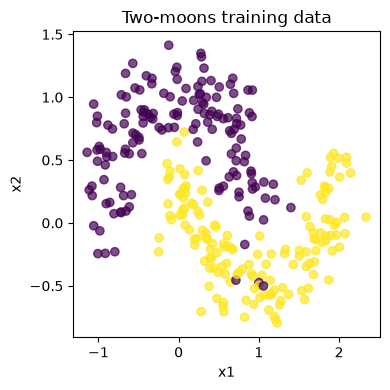

In [72]:
plt.figure(figsize=(4, 4))
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, alpha=0.7)
plt.title("Two-moons training data")
plt.xlabel("x1")
plt.ylabel("x2")
plt.tight_layout()

In [73]:
# Implementing the tiny MLP
# We use 2 input features, a small hidden layer, and 1 output:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_deriv(x):
    s = sigmoid(x)       # technically, this is not great -- we'd compute sigmoid externally and reuse it here
    return s * (1 - s)

def bce_loss(y_hat, y_true, eps=1e-8):
    # limits the values of an array to a specified minimum and maximum interval
    # a a_min a_max
    y_hat = np.clip(y_hat, eps, 1 - eps)
    return -np.mean(y_true * np.log(y_hat) + (1 - y_true) * np.log(1 - y_hat))

d = 2      # input dim
m = 8      # hidden units
rng = np.random.default_rng(0)

# Initialize parameters
W = rng.normal(scale=0.5, size=(m, d))
b = np.zeros(m)
v = rng.normal(scale=0.5, size=(m,))
c = 0.0

def forward(X):
    """
    X: (n, d)
    returns (a, h, u, y_hat)
    """
    a = X @ W.T + b          # (n, m)
    # hidden layer
    h = sigmoid(a)           # (n, m)
    u = h @ v + c            # (n,)
    # output
    y_hat = sigmoid(u)       # (n,)
    return a, h, u, y_hat

In [74]:
# One training step with manual backprop
# forward, then backward
def train_step(X_batch, y_batch, W, b, v, c, lr=0.1):
    n = X_batch.shape[0]
    # Forward pass
    a, h, u, y_hat = forward(X_batch)
    loss = bce_loss(y_hat, y_batch)

    # Backward pass
    # dL/du
    dL_du = (y_hat - y_batch) / n  # (n,); here we're taking an average over the batch, as foretold

    # dL/dv and dL/dc
    dL_dv = h.T @ dL_du            # (m,)
    dL_dc = np.sum(dL_du)          # scalar

    # dL/dh
    dL_dh = np.outer(dL_du, v)     # (n, m)

    # dL/da via sigmoid derivative
    dL_da = dL_dh * sigmoid_deriv(a)  # (n, m)

    # dL/dW, dL/db
    dL_dW = dL_da.T @ X_batch      # (m, d)
    dL_db = np.sum(dL_da, axis=0)  # (m,)

    # Gradient step
    W -= lr * dL_dW
    b -= lr * dL_db
    v -= lr * dL_dv
    c -= lr * dL_dc

    return loss, W, b, v, c

In [75]:
# Training loop & loss curves
def train_manual(X_train, y_train, X_val, y_val,
                 epochs=200, batch_size=64, lr=0.1):
    global W, b, v, c
    n = X_train.shape[0]
    # keep track of the train and validation losses at each epoch.
    history = {"epoch": [], "train_loss": [], "val_loss": []}
    rng = np.random.default_rng(1)

    for epoch in range(1, epochs + 1):
        # Mini-batch SGD
        perm = rng.permutation(n)
        X_shuff = X_train[perm]
        y_shuff = y_train[perm]

        for i in range(0, n, batch_size):
            X_batch = X_shuff[i:i+batch_size]
            y_batch = y_shuff[i:i+batch_size]
            # compute the forward pass, calculate gradients via manual backpropagation,
            # update the weights/biases in-place, and return the modified parameters.
            loss, W, b, v, c = train_step(
                X_batch, y_batch, W, b, v, c, lr=lr
            )

        # Track losses
        _, _, _, y_hat_train = forward(X_train)
        _, _, _, y_hat_val = forward(X_val)
        train_loss = bce_loss(y_hat_train, y_train)
        val_loss = bce_loss(y_hat_val, y_val)

        history["epoch"].append(epoch)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

    return pd.DataFrame(history)

hist_df = train_manual(X_train, y_train, X_val, y_val,
                       epochs=150, batch_size=64, lr=0.1)
hist_df.tail()

,epoch,train_loss,val_loss
145,146,0.336593,0.329225
146,147,0.336040,0.328634
147,148,0.335487,0.328349
148,149,0.334935,0.328013
149,150,0.334407,0.327439


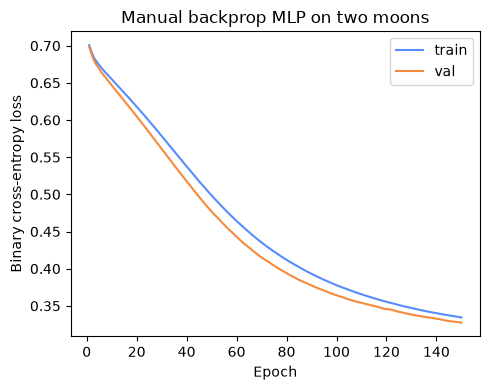

In [76]:
plt.figure(figsize=(5, 4))
plt.plot(hist_df["epoch"], hist_df["train_loss"], label="train")
plt.plot(hist_df["epoch"], hist_df["val_loss"], label="val")
plt.xlabel("Epoch")
# Cross-entropy loss (also known as log loss) measures
# the difference between a model's predicted probability distribution
# and the true label distribution in classification tasks.
plt.ylabel("Binary cross-entropy loss")
plt.title("Manual backprop MLP on two moons")
plt.legend()
plt.tight_layout()

In [77]:
# Show a small table of selected epochs
sampled = hist_df.iloc[::30, :].reset_index(drop=True)
sampled

,epoch,train_loss,val_loss
0,1,0.700650,0.698315
1,31,0.574500,0.556877
2,61,0.461064,0.439762
3,91,0.391449,0.375889
4,121,0.354569,0.345354


In [78]:
# Example gradient check (one parameter)
def loss_for_params(W, b, v, c, X_batch, y_batch):
    _, _, _, y_hat = forward(X_batch)
    return bce_loss(y_hat, y_batch)

# Pick a tiny batch
X_small = X_train[:5]
y_small = y_train[:5]

# Compute backprop gradient for v[0]
_, h, u, y_hat = forward(X_small)
dL_du = (y_hat - y_small) / len(X_small)
dL_dv_backprop = (h.T @ dL_du)[0]  # gradient for v[0]

# Finite difference gradient
eps = 1e-5
v_perturb = v.copy()
v_perturb[0] += eps
loss_plus = loss_for_params(W, b, v_perturb, c, X_small, y_small)

v_perturb[0] -= 2 * eps
loss_minus = loss_for_params(W, b, v_perturb, c, X_small, y_small)

dL_dv_fd = (loss_plus - loss_minus) / (2 * eps)
dL_dv_backprop, dL_dv_fd
# If these two numbers are close (e.g., relative error < 1e-3),
# our gradient for that parameter is likely correct.

(np.float64(0.043839416812162045), np.float64(0.0))

In [79]:
def check_grad_v_component(idx, eps=1e-5):
    X_small = X_train[:5]
    y_small = y_train[:5]

    # Backprop
    _, h, u, y_hat = forward(X_small)
    dL_du = (y_hat - y_small) / len(X_small)
    dL_dv_backprop = (h.T @ dL_du)[idx]

    # Finite difference
    v_perturb = v.copy()
    v_perturb[idx] += eps
    loss_plus = loss_for_params(W, b, v_perturb, c, X_small, y_small)

    v_perturb[idx] -= 2 * eps
    loss_minus = loss_for_params(W, b, v_perturb, c, X_small, y_small)

    dL_dv_fd = (loss_plus - loss_minus) / (2 * eps)
    rel_err = np.abs(dL_dv_backprop - dL_dv_fd) / (np.abs(dL_dv_fd) + 1e-8)
    return dL_dv_backprop, dL_dv_fd, rel_err

rows = []
for idx in range(min(5, len(v))):
    g_back, g_fd, rel_err = check_grad_v_component(idx)
    rows.append({
        "index": idx,
        "grad_backprop": g_back,
        "grad_finite_diff": g_fd,
        "relative_error": rel_err
    })

pd.DataFrame(rows)

,index,grad_backprop,grad_finite_diff,relative_error
0,0,0.043839,0.0,4.383942e+06
1,1,0.031211,0.0,3.121084e+06
2,2,0.039205,0.0,3.920467e+06
3,3,0.005649,0.0,5.648833e+05
4,4,0.014880,0.0,1.488018e+06


In [80]:
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(3151)

# convert np training and validation data to pytorch FloatTensors
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
X_val_t   = torch.tensor(X_val, dtype=torch.float32)
y_val_t   = torch.tensor(y_val, dtype=torch.float32).unsqueeze(1)

# wrap together
train_ds = TensorDataset(X_train_t, y_train_t)
val_ds   = TensorDataset(X_val_t, y_val_t)

# handles the automatic batching and shuffling of the training set
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
val_loader   = DataLoader(val_ds, batch_size=256, shuffle=False)

In [81]:
# nn: neural network
class TinyMLP(nn.Module):
    def __init__(self, d_in=2, d_hidden=8):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_in, d_hidden),
            nn.Sigmoid(),
            nn.Linear(d_hidden, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.net(x)

model = TinyMLP()
criterion = nn.BCELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

In [82]:
# Training loop with autograd
def train_with_autograd(model, train_loader, val_loader, epochs=50):
    history = {"epoch": [], "train_loss": [], "val_loss": []}

    for epoch in range(1, epochs + 1):
        model.train()
        running_loss = 0.0
        n_train = 0

        for Xb, yb in train_loader:
            optimizer.zero_grad()        # IMPORTANT: clear old gradients
            yhat = model(Xb)             # forward pass
            loss = criterion(yhat, yb)
            loss.backward()              # backprop: compute gradients
            optimizer.step()             # SGD step

            running_loss += loss.item() * Xb.size(0)
            n_train += Xb.size(0)

        train_loss = running_loss / n_train

        # Validation
        model.eval()
        with torch.no_grad():
            val_loss = 0.0
            n_val = 0
            for Xb, yb in val_loader:
                yhat = model(Xb)
                loss = criterion(yhat, yb)
                val_loss += loss.item() * Xb.size(0)
                n_val += Xb.size(0)
        val_loss /= n_val

        history["epoch"].append(epoch)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

    return pd.DataFrame(history)

hist_torch = train_with_autograd(model, train_loader, val_loader, epochs=140)
hist_torch.tail()

,epoch,train_loss,val_loss
135,136,0.325788,0.318450
136,137,0.325113,0.317906
137,138,0.324761,0.317429
138,139,0.324537,0.317131
139,140,0.324171,0.316567


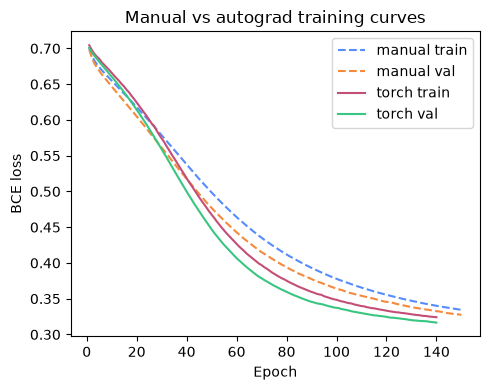

In [83]:
# Comparing loss curves: manual vs autograd
plt.figure(figsize=(5, 4))
plt.plot(hist_df["epoch"], hist_df["train_loss"], label="manual train", linestyle="--")
plt.plot(hist_df["epoch"], hist_df["val_loss"], label="manual val", linestyle="--")
plt.plot(hist_torch["epoch"], hist_torch["train_loss"], label="torch train")
plt.plot(hist_torch["epoch"], hist_torch["val_loss"], label="torch val")
plt.xlabel("Epoch")
plt.ylabel("BCE loss")
plt.title("Manual vs autograd training curves")
plt.legend()
plt.tight_layout()

In [84]:
# Simple accuracy function
def accuracy_from_logits(model, X, y):
    model.eval()
    with torch.no_grad():
        logits = model(torch.tensor(X, dtype=torch.float32))
        preds = (logits.numpy().ravel() > 0.5).astype(int)
    return np.mean(preds == y)

acc_train_torch = accuracy_from_logits(model, X_train, y_train)
acc_val_torch   = accuracy_from_logits(model, X_val, y_val)

# For manual model, recompute predictions using the current W, b, v, c
_, _, _, yhat_train_manual = forward(X_train)
_, _, _, yhat_val_manual   = forward(X_val)

acc_train_manual = np.mean((yhat_train_manual > 0.5).astype(int) == y_train)
acc_val_manual   = np.mean((yhat_val_manual > 0.5).astype(int) == y_val)

pd.DataFrame({
    "model": ["manual MLP", "torch MLP"],
    "train_acc": [acc_train_manual, acc_train_torch],
    "val_acc": [acc_val_manual, acc_val_torch]
})

,model,train_acc,val_acc
0,manual MLP,0.84,0.82
1,torch MLP,0.85,0.82
